# 00: package examples (MediaPipe and RTMPose on one still)

Goal: get used to the workflow, not to measure anything. Runs both pose models on one public sample image, draws the skeletons, compares the joints they share, computes one elbow angle, and times them on this CPU.

Inputs: `data/examples/mediapipe_sample_person.jpg` (the image from MediaPipe's own example), weights in `models/`. Nothing is written to disk.

In [1]:
import os, time
from pathlib import Path
os.environ["GLOG_minloglevel"] = "2"  # quieter MediaPipe logs

import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks.python import BaseOptions, vision
from rtmlib import Body

ROOT = Path.cwd().resolve().parent  # notebooks/ -> project root
IMG = ROOT / "data/examples/mediapipe_sample_person.jpg"
MP_MODEL = ROOT / "models/mediapipe/pose_landmarker_full.task"
DET_MODEL = ROOT / "models/rtmlib/yolox_m_humanart.onnx"
POSE_MODEL = ROOT / "models/rtmlib/rtmpose_m_body7_256x192.onnx"

bgr = cv2.imread(str(IMG))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
H, W = rgb.shape[:2]
print(f"image {W}x{H}, mediapipe {mp.__version__}")

image 960x640, mediapipe 1.2.3


## 1. MediaPipe Pose Landmarker (IMAGE mode)
Output: 33 landmarks, `x, y` normalized to [0, 1] by image width and height, `z` relative depth (model-estimated), `visibility` and `presence` scores. For video files use `RunningMode.VIDEO` and `detect_for_video(image, timestamp_ms)` with increasing timestamps.

In [2]:
opts = vision.PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(MP_MODEL)),
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1,
)
landmarker = vision.PoseLandmarker.create_from_options(opts)
res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))

lm = res.pose_landmarks[0]
mp_xy = np.array([[p.x * W, p.y * H] for p in lm])  # pixels
mp_vis = np.array([p.visibility for p in lm])
print("landmarks:", len(lm))
print("first landmark (nose):", lm[0])

landmarks: 33
first landmark (nose): NormalizedLandmark(x=0.3417133688926697, y=0.19891542196273804, z=-0.22425667941570282, visibility=0.9999980926513672, presence=0.9999978542327881, name=None)


INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7d92b40034a0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7d92b406d410, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
W0000 00:00:1794873408.957225   25146 inference_runner_litert.cc:1433] Input tensor memory is not aligned according to LiteRt's memory alignment requirements. Reallocating memory and copying data.
W0000 00:00:1794873409.015246   25143 landmark_projection_calculator.cc:81] Using NORM_RECT without I

## 2. RTMPose via rtmlib (top-down: YOLOX person detector, then RTMPose per box)
Output: `keypoints` shape (persons, 17, 2) in pixels, COCO order; `scores` (persons, 17) from the SimCC head. The weights are loaded from `models/` by path, so rtmlib does not download anything.

In [3]:
body = Body(det=str(DET_MODEL), det_input_size=(640, 640),
            pose=str(POSE_MODEL), pose_input_size=(192, 256),
            backend="onnxruntime", device="cpu")
kpts, scores = body(bgr)  # rtmlib expects BGR
rtm_xy, rtm_sc = kpts[0], scores[0]
print("keypoints", kpts.shape, "scores", scores.shape)

load /home/sebas/HobbyProjects/pose-tracker/models/rtmlib/yolox_m_humanart.onnx with onnxruntime backend
load /home/sebas/HobbyProjects/pose-tracker/models/rtmlib/rtmpose_m_body7_256x192.onnx with onnxruntime backend


keypoints (1, 17, 2) scores (1, 17)


## 3. Skeletons side by side
COCO 17-keypoint order is used for both; MediaPipe's 33 landmarks are mapped onto it (`MP_TO_COCO`).

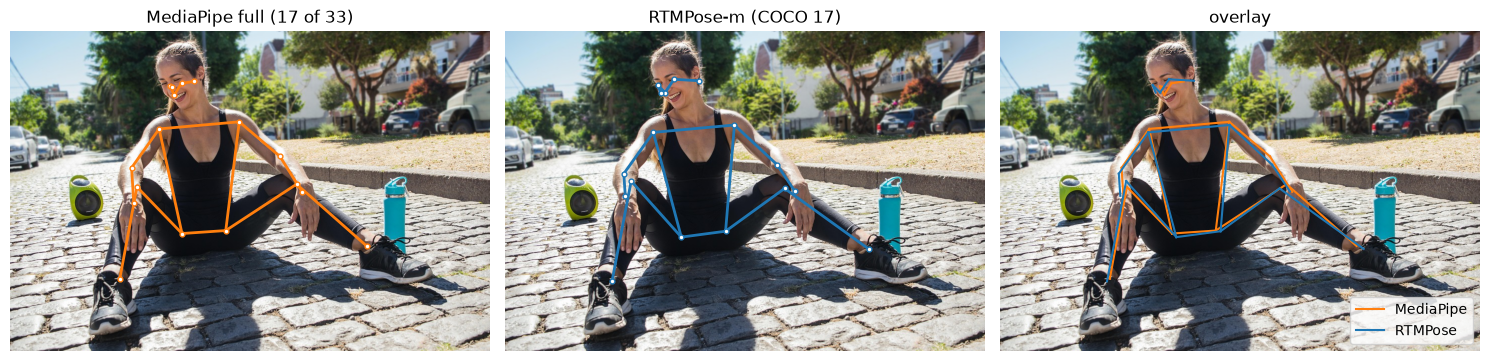

In [4]:
COCO = ["nose", "l_eye", "r_eye", "l_ear", "r_ear", "l_shoulder", "r_shoulder", "l_elbow", "r_elbow",
        "l_wrist", "r_wrist", "l_hip", "r_hip", "l_knee", "r_knee", "l_ankle", "r_ankle"]
MP_TO_COCO = [0, 2, 5, 7, 8, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]
EDGES = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12),
         (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]

mp17 = mp_xy[MP_TO_COCO]

def draw(ax, xy, color, title):
    ax.imshow(rgb)
    for a, b in EDGES:
        ax.plot(*xy[[a, b]].T, color=color, lw=2)
    ax.scatter(*xy.T, s=12, color="white", edgecolor=color, zorder=3)
    ax.set_title(title); ax.axis("off")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
draw(axs[0], mp17, "tab:orange", "MediaPipe full (17 of 33)")
draw(axs[1], rtm_xy, "tab:blue", "RTMPose-m (COCO 17)")
axs[2].imshow(rgb)
for xy, c, name in [(mp17, "tab:orange", "MediaPipe"), (rtm_xy, "tab:blue", "RTMPose")]:
    for a, b in EDGES:
        axs[2].plot(*xy[[a, b]].T, color=c, lw=1.5)
    axs[2].plot([], [], color=c, label=name)
axs[2].legend(loc="lower right"); axs[2].set_title("overlay"); axs[2].axis("off")
plt.tight_layout(); plt.show()

## 4. How far apart are the two models?
Pixel distance per shared joint. No ground truth here, so this is disagreement, not error. Scores are printed for orientation only: MediaPipe visibility and RTMPose SimCC confidence mean different things and are not comparable.

In [5]:
d = np.linalg.norm(mp17 - rtm_xy, axis=1)
torso = np.linalg.norm(rtm_xy[5] - rtm_xy[12])  # l_shoulder to r_hip, a rough body scale
print(f"{'joint':<11} {'dist_px':>7} {'% torso':>7} {'mp_vis':>6} {'rtm_sc':>6}")
for j, name in enumerate(COCO):
    print(f"{name:<11} {d[j]:7.1f} {100*d[j]/torso:7.1f} {mp_vis[MP_TO_COCO[j]]:6.2f} {rtm_sc[j]:6.2f}")
print(f"median {np.median(d):.1f} px, max {d.max():.1f} px ({COCO[d.argmax()]}); torso {torso:.0f} px")

joint       dist_px % torso mp_vis rtm_sc
nose            9.6     3.9   1.00   0.88
l_eye           9.6     3.9   1.00   0.92
r_eye          14.7     5.9   1.00   0.93
l_ear          20.3     8.2   1.00   0.96
r_ear          17.5     7.0   1.00   0.90
l_shoulder      6.4     2.6   1.00   0.94
r_shoulder      7.1     2.9   1.00   0.98
l_elbow        17.3     7.0   0.98   0.78
r_elbow        13.1     5.3   0.96   0.83
l_wrist         4.6     1.8   0.94   0.65
r_wrist        16.8     6.8   0.95   0.78
l_hip           9.7     3.9   1.00   0.83
r_hip          11.2     4.5   1.00   0.84
l_knee         16.3     6.6   0.96   0.83
r_knee         11.8     4.8   0.98   0.73
l_ankle        15.3     6.2   0.97   0.86
r_ankle         7.5     3.0   0.97   0.78
median 11.8 px, max 20.3 px (l_ear); torso 248 px


## 5. One joint angle: elbow (shoulder-elbow-wrist), in the image plane
This is the kind of number the stroke analyzer reports. A 2D angle depends on camera view; it equals the true angle only if the arm lies in a plane parallel to the image.

In [6]:
def angle_deg(a, b, c):
    """Angle at b, between b->a and b->c, in degrees."""
    u, v = a - b, c - b
    return np.degrees(np.arccos(np.clip(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)), -1, 1)))

for side, (s, e, w) in {"left": (5, 7, 9), "right": (6, 8, 10)}.items():
    print(f"{side:>5} elbow: MediaPipe {angle_deg(*mp17[[s, e, w]]):6.1f} deg, "
          f"RTMPose {angle_deg(*rtm_xy[[s, e, w]]):6.1f} deg")

 left elbow: MediaPipe  162.4 deg, RTMPose  166.6 deg
right elbow: MediaPipe  141.0 deg, RTMPose  140.6 deg


## 6. CPU timing on this laptop (i7-1165G7)
Median of 20 runs after one warm-up, single image, 960x640. RTMPose time includes the YOLOX person detector, which dominates. In video, the detector can run every N frames (rtmlib's `PoseTracker`), so per-frame cost will be lower.

In [7]:
def bench(fn, n=20):
    fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return 1000 * np.median(t)

mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
t_mp = bench(lambda: landmarker.detect(mp_img))
t_det = bench(lambda: body.det_model(bgr))
t_rtm = bench(lambda: body(bgr))
print(f"MediaPipe full:          {t_mp:6.1f} ms/img  ({1000/t_mp:5.1f} img/s)")
print(f"RTMPose-m + YOLOX-m:     {t_rtm:6.1f} ms/img  ({1000/t_rtm:5.1f} img/s)")
print(f"  of which YOLOX-m det:  {t_det:6.1f} ms")
print(f"CPU threads seen: {os.cpu_count()}")

MediaPipe full:            37.0 ms/img  ( 27.0 img/s)
RTMPose-m + YOLOX-m:      290.4 ms/img  (  3.4 img/s)
  of which YOLOX-m det:   236.4 ms
CPU threads seen: 8


In [8]:
landmarker.close()

INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7d92b40034a0, name=CpuAccelerator
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7d92b406d410, name=CpuAccelerator


## Takeaways (from the run saved in this notebook, 2026-11-16; one image, not a benchmark)
- Both models find the person and agree to a median of about 12 px (about 5 % of the torso diagonal). The largest gaps are at the ears and the left elbow and knee (16-20 px), not at the wrists. Without ground truth this is disagreement, not error: the hand labels in M3 decide which model is right.
- Some gaps are systematic: the two models were trained on different keypoint definitions (e.g. where exactly a hip or ear is), so a constant offset between models is expected and does not mean one is wrong.
- Elbow angles agree within about 4 deg here, on a slow, well-lit, unblurred pose. Fast strokes will be harder.
- CPU cost: MediaPipe full is about 8x faster than RTMPose-m + YOLOX-m, and the YOLOX-m detector is about 80 % of the RTMPose time. For video, detect every N frames or use a lighter detector.
- Next: the same comparison on our own stills (M1), side and front views.